In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("All libraries imported successfully!")

All libraries imported successfully!


In [22]:

import pandas as pd

df = pd.read_csv("/content/dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Column names:", df.columns.tolist())
print("\nFirst five rows:")
print(df.head())


Dataset loaded successfully!
Dataset shape: (22000, 2)
Column names: ['Text', 'language']

First five rows:
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [23]:

# Step 5: Clean and preprocess the dataset

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove rows with missing text or language
df = df.dropna(subset=["Text", "language"])

# Remove empty text and language values
df["Text"] = df["Text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[(df["Text"] != "") & (df["language"] != "")]

# Remove duplicate records
df = df.drop_duplicates(subset=["Text", "language"])

# Reset row numbers
df = df.reset_index(drop=True)

print("\nDataset after cleaning:", df.shape)
print("\nNumber of languages:", df["language"].nunique())
print("\nLanguage distribution:")
print(df["language"].value_counts())

print("\nPreprocessing completed successfully!")


Missing values before cleaning:
Text        0
language    0
dtype: int64

Dataset after cleaning: (21858, 2)

Number of languages: 22

Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64

Preprocessing completed successfully!


In [24]:

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["language"])

print("Language labels created successfully!")

print("\nLanguage mapping:")
for i, language in enumerate(label_encoder.classes_):
    print(i, "=", language)

print("\nFirst five labelled samples:")
print(df[["Text", "language", "label"]].head())


Language labels created successfully!

Language mapping:
0 = Arabic
1 = Chinese
2 = Dutch
3 = English
4 = Estonian
5 = French
6 = Hindi
7 = Indonesian
8 = Japanese
9 = Korean
10 = Latin
11 = Persian
12 = Portugese
13 = Pushto
14 = Romanian
15 = Russian
16 = Spanish
17 = Swedish
18 = Tamil
19 = Thai
20 = Turkish
21 = Urdu

First five labelled samples:
                                                Text  language  label
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian      4
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish     17
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai     19
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil     18
4  de spons behoort tot het geslacht haliclona en...     Dutch      2


In [25]:

from sklearn.model_selection import train_test_split

X = df["Text"].values
y = df["label"].values

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train_text))
print("Testing samples:", len(X_test_text))
print("Data splitting completed successfully!")


Training samples: 17486
Testing samples: 4372
Data splitting completed successfully!


In [26]:

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Set parameters
vocab_size = 20000
max_length = 100

# Tokenize text
tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

# Convert text into numerical sequences
X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

# Pad sequences
X_train = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Get vocabulary and class information
actual_vocab_size = min(
    vocab_size, len(tokenizer.word_index) + 1
)

num_classes = len(label_encoder.classes_)

print("Tokenization and padding completed!")
print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Vocabulary size:", actual_vocab_size)
print("Number of languages:", num_classes)


Tokenization and padding completed!
Training data shape: (17486, 100)
Testing data shape: (4372, 100)
Vocabulary size: 20000
Number of languages: 22


In [28]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Build the LSTM model
model = Sequential([
    Embedding(
        input_dim=actual_vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

# Compile the model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model structure
model.summary()

# Stop training when validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

# Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 38s 143ms/step - accuracy: 0.3151 - loss: 2.1768 - val_accuracy: 0.7198 - val_loss: 1.0351
Epoch 2/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - accuracy: 0.7056 - loss: 0.9151 - val_accuracy: 0.7976 - val_loss: 0.5452
Epoch 3/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - accuracy: 0.8120 - loss: 0.5832 - val_accuracy: 0.9051 - val_loss: 0.3077
Epoch 4/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 26s 107ms/step - accuracy: 0.8889 - loss: 0.3760 - val_accuracy: 0.9262 - val_loss: 0.2288
Epoch 5/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 41s 109ms/step - accuracy: 0.9161 - loss: 0.2677 - val_accuracy: 0.9217 - val_loss: 0.2000
Epoch 6/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 26s 106ms/step - accuracy: 0.9149 - loss: 0.2529 - val_accuracy: 0.9348 - val_loss: 0.2000
Epoch 7/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - accuracy: 0.9301 - loss: 0.1987 - val_accuracy: 0.9371 - val_loss: 0.1838
Epoch 8/10
246/246 ━━━━━━━━━━━━━━━━━━━━ 27s 109ms/step - accuracy: 0.9242 - loss: 0

In [29]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Predict test samples
y_prob = model.predict(X_test, verbose=0)
y_pred = y_prob.argmax(axis=1)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("LSTM MODEL EVALUATION")
print("---------------------")
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=range(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))


LSTM MODEL EVALUATION
---------------------
Accuracy  : 0.9268
Precision : 0.9287
Recall    : 0.9270
F1-score  : 0.9269

Classification Report:
              precision    recall  f1-score   support

      Arabic       1.00      0.99      0.99       200
     Chinese       0.53      0.65      0.59       200
       Dutch       0.99      1.00      0.99       199
     English       0.86      0.96      0.91       200
    Estonian       0.99      0.93      0.96       200
      French       0.96      0.98      0.97       198
       Hindi       0.99      0.96      0.98       198
  Indonesian       0.98      0.98      0.98       195
    Japanese       0.50      0.40      0.45       200
      Korean       0.99      0.98      0.99       200
       Latin       0.97      0.92      0.95       191
     Persian       0.99      0.99      0.99       200
   Portugese       0.98      0.98      0.98       199
      Pushto       0.99      0.93      0.96       199
    Romanian       0.98      0.97      0.98  

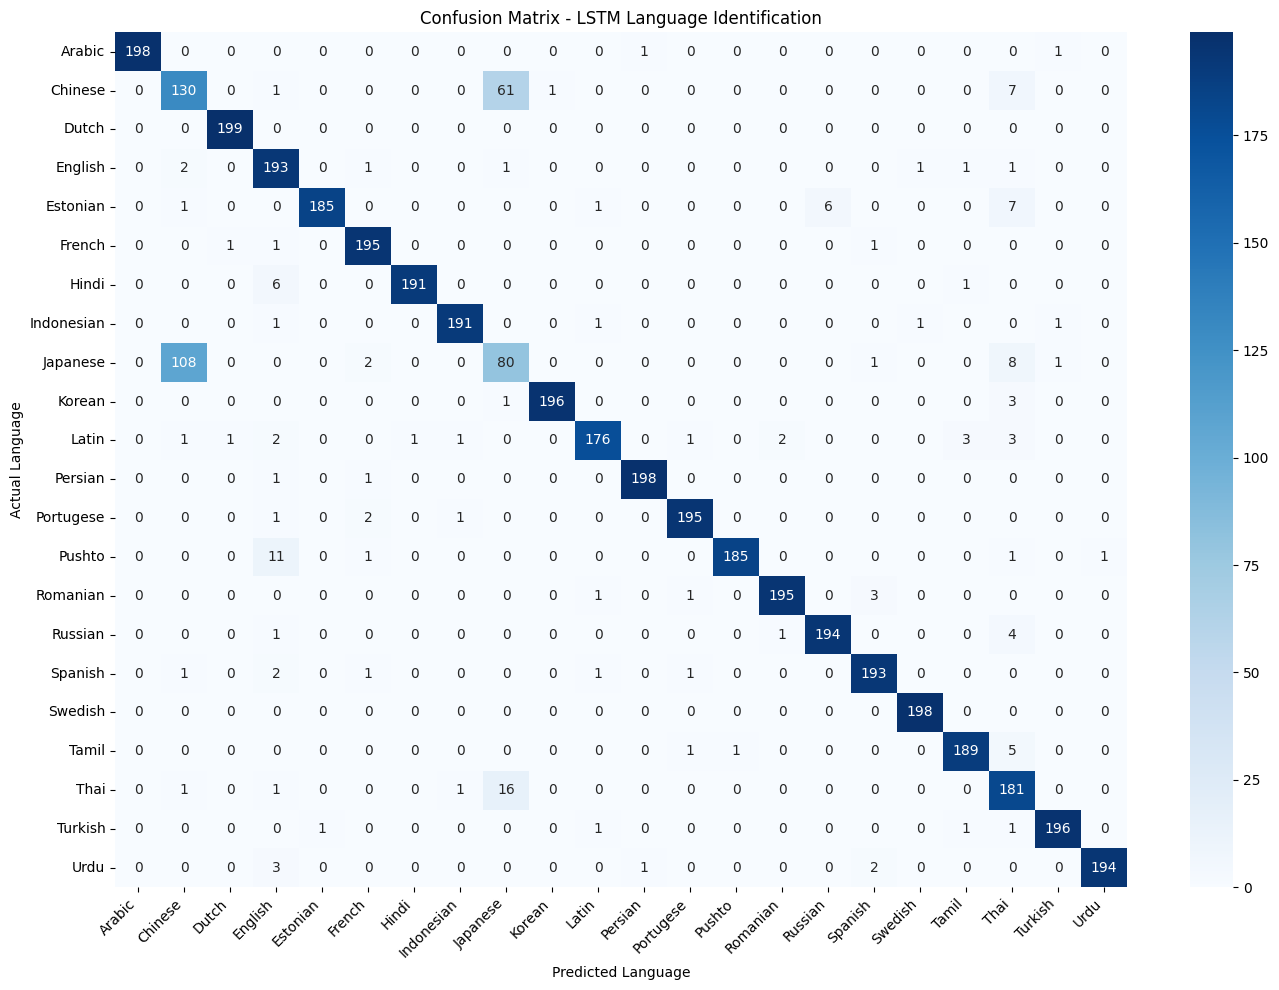

In [30]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(num_classes)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - LSTM Language Identification")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


In [31]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

# Five unseen text samples
unseen_texts = [
    "The weather is beautiful today.",
    "Bonjour, comment allez-vous ?",
    "Hola, ¿cómo estás?",
    "Guten Morgen, wie geht es dir?",
    "Ciao, come stai oggi?"
]

# Convert text into numerical sequences
sequences = tokenizer.texts_to_sequences(unseen_texts)

# Pad sequences
padded = pad_sequences(
    sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

# Predict the languages
predictions = model.predict(padded, verbose=0)

print("LANGUAGE PREDICTION RESULTS")
print("---------------------------")

for text, probs in zip(unseen_texts, predictions):
    index = probs.argmax()
    language = label_encoder.inverse_transform([index])[0]
    confidence = probs[index] * 100

    print("\nText:", text)
    print("Predicted language:", language)
    print(f"Confidence: {confidence:.2f}%")


LANGUAGE PREDICTION RESULTS
---------------------------

Text: The weather is beautiful today.
Predicted language: English
Confidence: 18.16%

Text: Bonjour, comment allez-vous ?
Predicted language: Japanese
Confidence: 44.36%

Text: Hola, ¿cómo estás?
Predicted language: Japanese
Confidence: 48.37%

Text: Guten Morgen, wie geht es dir?
Predicted language: Spanish
Confidence: 30.85%

Text: Ciao, come stai oggi?
Predicted language: Japanese
Confidence: 48.74%
